# scikit-learn-基本功能

## 教學目標

這份教學的目標是介紹基本的 `scikit-learn` 功能，並學習撰寫機器學習的程式碼。

## 適用對象

適用於有程式基礎，且擁有 python、`numpy`、`pandas` 與 `matplotlib` 基礎的學生。

若沒有先學過 Python，建議先補充 Python 入門語法。

若沒有先學過 `numpy`，請參考 [numpy-基本功能](./numpy-基本功能.ipynb) 教學。

若沒有先學過 `pandas`，請參考 [pandas-基本功能](./pandas-基本功能.ipynb) 教學。

若沒有先學過 `matplotlib`，請參考 [matplotlib-資料視覺化](./matplotlib-資料視覺化.ipynb) 教學。

## 原教材的執行時間與測試環境

以下是原教材的測試記錄，實際執行時間會因內容與環境而不同。

本教學全部執行時間約為 2.0011203289031982 秒。

|測試環境|名稱|
|-|-|
|主機板|X570 AORUS ELITE|
|處理器|AMD Ryzen 7 3700X 8-Core Processor|
|記憶體|Kingston KHX3200C16D4/16GX|
|硬碟|Seagate ST1000DM003-1ER1|
|顯示卡|GeForce RTX 2080|
|作業系統|Ubuntu 18.04 LTS|

套件安裝與教材導覽請參考 [使用說明](./README.md)。

## 大綱

- [簡介](#簡介)
- [安裝](#安裝)
- [機器學習流程](#機器學習流程)
- [資料前處理](#資料前處理)
- [機器學習模型](#機器學習模型)
- [模型驗證](#模型驗證)
- [評估方法](#評估方法)
- [練習](#練習)

## 簡介

`scikit-learn` 是以 python 為介面的**機器學習函式庫**，提供種類豐富的**機器學習模型**與**分析工具**，能夠套用在各式各樣的資料集上。

根據 [scikit-learn 官方網站](https://scikit-learn.org/stable/)（v0.22）：

> Simple and efficient tools for predictive data analysis
> 
> 簡單且有效率的預測型資料分析工具
> 
> Accessible to everybody, and reusable in various contexts
>
> 容易取得，能夠在不同的環境下重複利用執行結果
>
> Built on NumPy, SciPy, and matplotlib
>
> 基於 `numpy`、`scipy` 與 `matplotlib` 等工具進行開發
>
> Open source, commercially usable - BSD license
>
> 以 BSD 授權條款開源且可以進行商業使用

閱讀程式時，優先確認輸入特徵 `X`、答案 `y`、資料切分方式，以及評估指標。

## 安裝

環境已備妥可直接往下執行。缺少套件時，依 [使用說明](./README.md) 安裝。
安裝名稱是 `scikit-learn`，程式中的模組名稱是 `sklearn`。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 機器學習流程

1. 定義任務、輸入特徵與預測目標，切分訓練、驗證與測試資料。
2. 只用訓練資料學習前處理規則，並用 `model.fit(X, y)` 訓練模型。
3. 用 `model.predict(X)` 預測，以驗證資料比較模型與調整超參數，最後用測試資料評估。
4. 應用時沿用訓練時的前處理與模型，將預測轉成可解讀的結果。

先用已知關係 `y = 10x - 12` 示範訓練與預測。模型直接留在記憶體中，這裡不展開檔案儲存與載入。

In [2]:
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(42)
train_x = rng.uniform(0, 10, size=(10, 1))
print("訓練資料：", train_x)
train_y = 10 * train_x - 12
print("訓練標籤：", train_y)

model = LinearRegression(fit_intercept=True)
model.fit(train_x, train_y)
print("學到的斜率：", model.coef_, "截距：", model.intercept_)

訓練資料： [[7.73956049]
 [4.3887844 ]
 [8.5859792 ]
 [6.97368029]
 [0.94177348]
 [9.75622352]
 [7.61139702]
 [7.86064305]
 [1.28113633]
 [4.50385938]]
訓練標籤： [[65.39560486]
 [31.88784398]
 [73.85979199]
 [57.73680291]
 [-2.58226521]
 [85.56223516]
 [64.1139702 ]
 [66.60643053]
 [ 0.81136327]
 [33.03859379]]
學到的斜率： [[10.]] 截距： [-12.]


測試 R²： 1.0


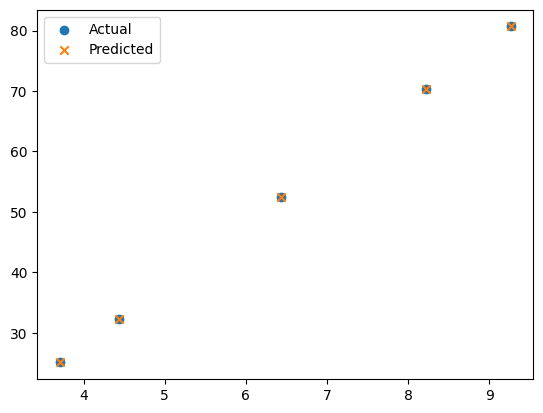

In [3]:
test_x = rng.uniform(0, 10, size=(5, 1))
test_y = 10 * test_x - 12
pred_y = model.predict(test_x)

print("測試 R²：", model.score(test_x, test_y))
plt.scatter(test_x, test_y, label='Actual')
plt.scatter(test_x, pred_y, marker='x', label='Predicted')
plt.legend()
plt.show()

In [4]:
# 單筆樣本仍以二維特徵輸入：(1 筆樣本, 1 個特徵)。
input_x = 1
output_y = model.predict([[input_x]])[0, 0]
print(f'輸入 {input_x}，預測 {output_y:.2f}')

輸入 1，預測 -2.00


對應練習：[第 8 題](./exercises.ipynb#exercise-8)。


## 資料前處理

讀取資料集後並對資料進行前處理，包含：

- 處理**不存在**或是**遺失**的值
- 去除**離群值（Outlier）**
- **取出**需要分析的資料欄位
- 針對**不同資料型態**進行特別處理，通常分為兩種型態：
    - **數值**型態
    - **類別**型態

### 資料集

以下使用 Kaggle Titanic 資料，根據乘客特徵預測是否生還。
將 [Titanic 資料集](https://www.kaggle.com/c/titanic/data) 的 `train.csv` 放到本目錄的 `data/`，
並從 `simplified` 目錄執行。資料需自行下載；後續練習沿用同一份檔案。

In [6]:
# 資料集
# 讀取訓練資料
train_df = pd.read_csv('./data/train.csv')
# 預覽訓練資料前 5 筆
train_df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
# 輸出訓練資料型態與大小
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
# X 為輸入特徵，y 為生還標記；copy 避免修改原始表格。
train_x = train_df[['Sex', 'Age']].copy()
train_y = train_df['Survived']
train_x.tail()

,Sex,Age
886,male,27.0
887,female,19.0
888,female,NaN
889,male,26.0
890,male,32.0


### 填補缺失值

`SimpleImputer` 用訓練資料學習填補值（`fit`），再套用規則（`transform`）。

|strategy|填補方式|
|---|---|
|`mean`|平均數|
|`median`|中位數|
|`most_frequent`|眾數|
|`constant`|由 `fill_value` 指定常數|

以下先示範填補 Age；正式驗證時會先切分資料，再只用訓練部分學習填補值。


In [9]:
# 查看資料缺失情形
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
imputer.fit(train_x[['Age']])
train_x['Age'] = imputer.transform(train_x[['Age']]).ravel()
train_x.tail(5)


,Sex,Age
886,male,27.000000
887,female,19.000000
888,female,29.699118
889,male,26.000000
890,male,32.000000


### 數值資料：常見處理方式

本例的決策樹不需要縮放特徵；以下先認識用途。

**標準化：** `StandardScaler` 使用 $z=(x-\mu)/\sigma$，讓訓練資料各欄位的平均值約為 0、標準差約為 1，不是限定在 [0, 1]，也不會把任意分布變成常態分布。

**用班級考試成績理解：** 小明考 80 分，小華考 60 分，單看分數，還不知道他們在班上算高還是低；如果全班大多考 90 分，80 分就偏低，如果全班大多考 50 分，80 分就很高。

假設全班平均為 70 分、標準差為 10 分，標準化後：

|成績|標準化計算|在群體中的相對位置|
|---|---|---|
|80 分|`(80 - 70) / 10 = 1`|高於平均 1 個標準差|
|70 分|`(70 - 70) / 10 = 0`|等於平均|
|60 分|`(60 - 70) / 10 = -1`|低於平均 1 個標準差|

因此，標準化是把「考幾分」改用「距離群體平均幾個標準差」來表示：正值代表平均以上，負值代表平均以下，數值的絕對值越大，代表離平均越遠。即使原本不知道分布的形狀，也能這樣理解相對位置，但還不能直接得知排名百分比。

**什麼時候可以說是前幾％？** 如果全班成績**近似常態分布**，`z = 1` 約高於 84% 的人，也就是前 16%；`z = 2` 約高於 97.7% 的人，也就是前 2.3%。如果成績分布偏斜或有多個群聚，這些百分比就不適用；要知道實際排名，應直接統計有多少人的成績低於或高於他。

![Normal Distribution](./images/scikit-learn/normal-distribution.png)

**轉換數值空間：** 對正數取 `np.log(x)`，可壓縮大數值的尺度，常用於右偏資料。

![Domain Transformation](./images/scikit-learn/domain-transformation.png)

**檢查離群值：先認識 Q1、Q3 與 IQR**

把資料由小到大排列後，可以用「四分位數」描述資料的位置：

|名稱|意思|直觀理解|
|---|---|---|
|$Q_1$：第一四分位數|第 25 百分位數|約 25% 的資料落在這個值以下|
|$Q_2$：第二四分位數|第 50 百分位數，也就是中位數|約一半的資料落在這個值以下|
|$Q_3$：第三四分位數|第 75 百分位數|約 75% 的資料落在這個值以下|

**IQR（Interquartile Range，四分位距）** 是 $Q_3-Q_1$，表示**中間約 50% 資料所涵蓋的數值範圍有多寬**。它是一個差值，不是資料筆數，也不是百分比。
在箱型圖中，箱子的兩端是 $Q_1$、$Q_3$，所以箱子的長度就是 IQR，箱內的線則是中位數 $Q_2$。

例如一個班級的考試成績，算出 $Q_1=60$ 分、$Q_3=80$ 分：

- 約 25% 的成績在 60 分以下，約 75% 在 80 分以下，中間約 50% 的成績落在 60～80 分。
- $IQR=80-60=20$ 分，表示中間這批成績的跨度是 20 分。
- 常用的離群值判定下界為 $Q_1-1.5IQR=60-30=30$ 分，上界為 $Q_3+1.5IQR=80+30=110$ 分。
- 因此，低於 30 分或高於 110 分的值會被標成可能的離群值；例如 20 分會被標出，但 95 分不會。剛好等於界線的值不算超出。

這個規則是找出「相對大多數資料特別遠」的點，不是在判定資料一定錯誤。20 分可能是真實成績，也可能是輸入錯誤，應先查原因再決定如何處理。
箱型圖的鬚通常延伸到界線內最遠的實際資料點，不一定剛好落在界線上。少量資料或重複值較多時，上述比例不一定精確；不同工具的百分位數插值方法也可能稍有差異。

![Quartile](./images/scikit-learn/quartiles.png)


### 類別資料：數字編碼與 One-hot

|方式|例子|注意事項|
|---|---|---|
|數字編碼|female → 0、male → 1|多個無序類別編成整數，可能讓模型誤以為有大小或距離關係|
|One-hot|female → [1, 0]、male → [0, 1]|每個類別對應一欄，欄位數會增加|

以下沿用 `LabelEncoder` 示範二元 Sex 欄位；它主要用於目標 y 的編碼，一般輸入特徵的無序類別可使用 `OneHotEncoder`。


In [11]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(train_x['Sex'])
train_x['Sex'] = le.transform(train_x['Sex'])
train_x.head(5)


,Sex,Age
0,1,22.0
1,0,38.0
2,0,26.0
3,0,35.0
4,1,35.0


In [12]:
# 額外示範 one-hot；不覆蓋後續決策樹使用的 train_x。
from sklearn.preprocessing import OneHotEncoder

onehot_enc = OneHotEncoder()
transformed = onehot_enc.fit_transform(train_df[['Sex']]).toarray()
print('轉換後 shape：', transformed.shape)
print(transformed[:5])


轉換後 shape： (891, 2)
[[0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]]


### 課堂互動：換個情境，你會怎麼判斷？

以下不需要寫程式，請運用前面學到的概念說明理由，約需 3 分鐘。

1. **數字一定是數值特徵嗎？** 學校想預測學生的考試成績，資料中有學號 `2026001`、`2026002` 等，每人學號都不同。有人建議：「學號是數字，先標準化；不然就把每個學號做成 One-hot，模型就能預測新學生。」你認為這兩種處理是否合理？學號的數字大小或差距，真的代表學習能力的差異嗎？
2. **不同班級的標準化分數能直接比原始成績嗎？** 小明在甲班、小華在乙班，參加同一份考試。兩班分別用各自的平均數與標準差做標準化，兩人的標準化分數都是 `z = 1`。是否能因此認定兩人的原始分數相同？還需要知道哪些資訊？

請與同學口頭討論，再分享你的判斷與理由。


## 機器學習模型

### 迴歸與分類

|任務|預測內容|本教材範例|
|---|---|---|
|迴歸|數值|前面的 LinearRegression，預測 y = 10x − 12|
|分類|類別|DecisionTreeClassifier，預測是否生還（0／1）|

![Linear Regression](./images/scikit-learn/linear-regression.png)

![Classification](./images/scikit-learn/classification.png)

本例有已知答案 `Survived`，屬於**監督式學習**。

### 模型參數與超參數

模型參數是 `fit()` 從資料學到的結果，例如線性迴歸的斜率、截距，以及決策樹的切分規則。
超參數則是訓練前指定的設定，例如 `max_depth` 限制決策樹深度；`random_state` 固定隨機性，方便重現結果。

先訓練一棵未限制深度的樹，再改成 `max_depth=2`。此處先看訓練 accuracy，下一節才用驗證資料比較泛化表現。


### 這棵決策樹要預測什麼？

我們使用 Titanic 乘客資料，讓模型根據**性別（Sex）與年齡（Age），預測這位乘客是否生還（Survived）**。

|資料|內容|一筆資料代表什麼|
|---|---|---|
|`train_x`：輸入特徵 X|`Sex`、`Age` 兩欄|一位乘客的性別與年齡；性別已轉成數字，缺失年齡已填補|
|`train_y`：正確答案 y|`Survived` 一欄|同一位乘客的實際結果：0 = 未生還，1 = 生還|

`train_x` 和 `train_y` 的每一列必須對應同一位乘客。
`model.fit(train_x, train_y)` 讓決策樹從特徵與正確答案學習切分規則；`model.predict(train_x)` 則依這些規則輸出每位乘客的預測結果（0 或 1）。

最後的 `accuracy_score` 比較預測結果與正確答案，計算答對的比例。這裡用的是模型已經看過的訓練資料，所以是**訓練 accuracy**，還不能代表對新乘客的預測能力。


In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

model = DecisionTreeClassifier(random_state=1012)
model.fit(train_x, train_y)
# print(train_x.head(5))
# print(train_y.head(5))
print('未限制深度的訓練 accuracy：', accuracy_score(train_y, model.predict(train_x)))


   Sex   Age
0    1  22.0
1    0  38.0
2    0  26.0
3    0  35.0
4    1  35.0
未限制深度的訓練 accuracy： 0.819304152637486


In [14]:
train_x.head(5)

,Sex,Age
0,1,22.0
1,0,38.0
2,0,26.0
3,0,35.0
4,1,35.0


In [20]:
train_y.head(5)

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [15]:
model = DecisionTreeClassifier(max_depth=2, random_state=1012)
model.fit(train_x, train_y)
print('深度為 2 的訓練 accuracy：', accuracy_score(train_y, model.predict(train_x)))


深度為 2 的訓練 accuracy： 0.7957351290684624


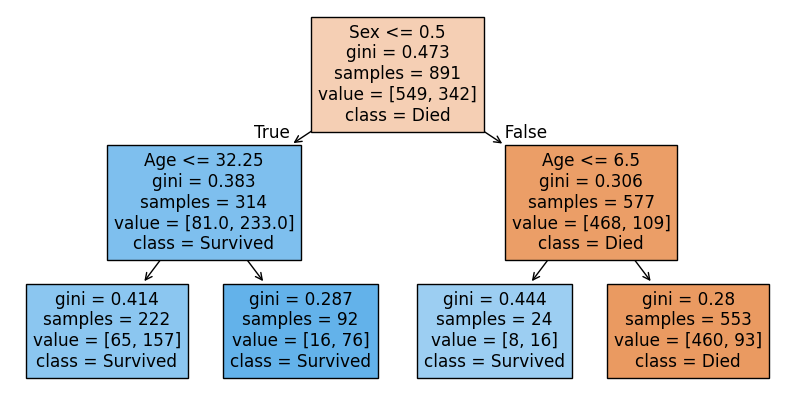

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(model, feature_names=list(train_x.columns), class_names=['Died', 'Survived'], filled=True, ax=ax)
plt.show()


## 模型驗證

![Overfitting & Underfitting](./images/scikit-learn/model-fitting.png)

|訓練表現|驗證表現|判讀與調整方向|
|---|---|---|
|不好|不好|可能欠擬合：增加模型複雜度或改善特徵|
|好|好|較能泛化到未見資料|
|好|不好|可能過度適應：限制樹深或增加資料|

### 為什麼會過度適應？模型可能把 noise 也學進去了

現實中，影響結果的因素往往非常複雜，我們收集到的特徵通常只能描述其中一部分。資料還可能受到測量誤差、偶然事件或未記錄因素的影響，所以即使輸入條件相似，結果也不一定完全相同。這些相對於目前特徵而言難以解釋的波動，可以視為**雜訊（noise）**。

例如用「讀書時數」預測考試成績，讀書較久可能整體表現較好，但同樣讀 3 小時的人，仍可能因當天精神、考題是否熟悉或臨場失誤而考出不同分數。模型應學到能在新資料中重現的整體關係，而不是認定某位學生那次多考或少考的幾分，是固定的規律。

可以先用這個簡化的想法理解：**觀測結果 = 可學習的規律 + 雜訊**。
模型太簡單時，連主要規律都抓不到，可能欠擬合；模型太複雜時，則可能為了配合每一筆訓練資料，把其中偶然的 noise 也當成規律學進去，形成**過度適應（overfitting）**。
新資料不會剛好出現相同的 noise，因此模型雖然在訓練資料上答得很好，在驗證資料上卻可能變差。

回頭看上方的曲線：適當的模型抓住整體趨勢；過度適應的模型為了貼近個別資料點而產生額外彎曲。決策樹也類似：樹太深時，可能用很細的規則記住少數樣本的偶然情況。因此我們要用未參與訓練的驗證資料，檢查模型學到的是可泛化的關係，還是訓練樣本特有的細節。

這是理解 overfitting 的常見方式；雜訊不一定代表資料錯誤，未記錄因素造成的差異也不一定是真正隨機的。訓練與驗證的差距也可能來自兩者的資料分布不同，仍需配合情境判斷。

`train_test_split` 將資料分成訓練與驗證兩部分。先切分原始資料，再只用訓練部分學習填補值與編碼規則，避免資料洩漏。
下面比較未限制深度與深度為 2 的樹，觀察訓練與驗證 accuracy 的差距。驗證資料用於選擇模型；最終評估應另留測試資料。


In [17]:
from sklearn.model_selection import train_test_split

# 從原始資料切分，不能沿用已對整份資料填補過的 train_x。
train_x_split, valid_x_split, train_y_split, valid_y_split = train_test_split(
    train_df[['Sex', 'Age']], train_df['Survived'],
    test_size=0.33, random_state=1012, stratify=train_df['Survived']
)
train_x_split = train_x_split.copy()
valid_x_split = valid_x_split.copy()

# 只在訓練部分 fit，驗證部分只 transform。
imputer = SimpleImputer(strategy='mean')
le = LabelEncoder()
train_x_split['Age'] = imputer.fit_transform(train_x_split[['Age']]).ravel()
valid_x_split['Age'] = imputer.transform(valid_x_split[['Age']]).ravel()
train_x_split['Sex'] = le.fit_transform(train_x_split['Sex'])
valid_x_split['Sex'] = le.transform(valid_x_split['Sex'])

for depth in [None, 2]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=1012)
    model.fit(train_x_split, train_y_split)
    train_acc = accuracy_score(train_y_split, model.predict(train_x_split))
    valid_acc = accuracy_score(valid_y_split, model.predict(valid_x_split))
    print(f'max_depth={depth}：train={train_acc:.3f}，valid={valid_acc:.3f}')


max_depth=None：train=0.826，valid=0.769
max_depth=2：train=0.790，valid=0.807


### 補充：交叉驗證（Cross Validation）

將資料分成 K 份，每份稱為一個 **Fold**；每次完整的訓練與驗證稱為一個 **Run**。
每個 Run 選一個 Fold 做驗證，將其餘 K−1 個 Fold 合在一起訓練模型，共進行 K 個 Run。

![K-fold Cross Validation](./images/scikit-learn/cross-validation.png)

以上圖的 5-fold 交叉驗證為例，**藍色是訓練資料，橘色是驗證資料**：

|Run|用哪些資料訓練模型？|用哪些資料驗證？|
|---|---|---|
|Run 1|Fold 2、3、4、5 合在一起|Fold 1|
|Run 2|Fold 1、3、4、5 合在一起|Fold 2|
|Run 3|Fold 1、2、4、5 合在一起|Fold 3|
|Run 4|Fold 1、2、3、5 合在一起|Fold 4|
|Run 5|Fold 1、2、3、4 合在一起|Fold 5|

因此，**每個 Run 都使用四個 Fold 的資料訓練，並用剩下的一個 Fold 驗證**。例如 Run 1 的 Fold 1 只負責驗證，不參與該次訓練。

每個 Run 都建立一個新的模型，從頭訓練，而不是接續上一個 Run 的模型繼續學習。
每次的前處理也只在該 Run 的訓練資料上 `fit`，再套用到該次驗證資料。
完成後得到 5 個驗證分數，通常取平均，並觀察分數的波動，了解模型對不同資料切分的穩定程度。
每個 Fold 恰好當過一次驗證資料；換到其他 Run 時則可作為訓練資料，因為各 Run 是獨立訓練的模型。

交叉驗證能減少只看一次切分的偶然性；若用它選擇模型或超參數，最終仍應用另外保留的測試資料評估。
本課先掌握前面的單次切分，交叉驗證概念可課後複習。


## 評估方法

迴歸常用 **MAE**（平均絕對誤差）或 **MSE**（均方誤差），兩者越小越好；MSE 對大誤差的懲罰較重。

分類先看混淆矩陣。以下將生還（1）視為陽性：

![Confusion Matrix](./images/scikit-learn/confusion-matrix.png)

|實際／預測|預測陽性|預測陰性|
|---|---|---|
|實際陽性|TP：正確找出|FN：漏掉|
|實際陰性|FP：誤報|TN：正確排除|

|指標|計算方式|回答的問題|
|---|---|---|
|Accuracy|$(TP+TN)/(TP+FP+FN+TN)$|全部樣本中有多少預測正確？|
|Precision|$TP/(TP+FP)$|預測陽性中有多少是真的？|
|Recall|$TP/(TP+FN)$|實際陽性中找到了多少？|
|F1|$2PR/(P+R)$，P、R 分別為 precision、recall|綜合 precision 與 recall 的表現如何？|

類別不平衡時，不能只看 accuracy；應根據漏報、誤報的代價選擇指標。


## 練習

沿用前面的 Titanic `data/train.csv`。

### 練習 1：改善決策樹分類模型

請改進 `sklearn.tree.DecisionTreeClassifier` 模型分類效果，可以嘗試：

- 增加更多的輸入特徵
- 使用不同的前處理方法
- 調整超參數

### 練習 2：使用不同的模型

請使用不同的模型打敗使用 `sklearn.tree.DecisionTreeClassifier` 模型分類效果，可以嘗試課堂所提過的方法：

|模型|名稱|
|-|-|
|[`sklearn.naive_bayes`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.naive_bayes)|樸素貝氏分類器（Naive Bayes Classifier）|
|[`sklearn.svm`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.svm)|支援向量機（Support Vector Machines）|
|[`sklearn.neighbors`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.neighbors)|近鄰演算法（Nearest Neighbors）|
|[`sklearn.ensemble`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.ensemble)|集合學習（Ensemble）|

In [ ]:
# 練習 1：請在此撰寫程式。


In [ ]:
# 練習 2：請在此撰寫程式。
